
This notebook analyzes synthetic demonstration data from a crossover experiment comparing professional writing performance with and without AI assistance.

**Primary metric:** Completion time (minutes).

**Secondary metrics:**
- Quality score
- Factual accuracy (%)
- Unsupported claim rate (%)

**Important:** This dataset is synthetic and is used only to demonstrate the analysis pipeline. It does not represent real experimental findings.

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_PATH = ROOT / "data" / "sample" / "example_measurements.csv"
PROCESSED_PATH = ROOT / "data" / "processed" / "metrics_summary.csv"
FIGURE_DIR = ROOT / "reports" / "figures"

print("Project root:", ROOT)
print("Raw dataset exists:", DATA_PATH.exists())
print("Processed CSV exists:", PROCESSED_PATH.exists())
print("Figures directory exists:", FIGURE_DIR.exists())


Project root: C:\Users\tasbo\genai-productivity-benchmark
Raw dataset exists: True
Processed CSV exists: True
Figures directory exists: True


In [2]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Number of participants:", df["participant_id"].nunique())

display(df.head())


Dataset shape: (8, 14)
Number of participants: 4


,participant_id,task_set,task_order,condition,completed,completion_time_minutes,quality_rater_1,quality_rater_2,factual_correct,factual_total,experience_years,data_origin,supported_claims,unsupported_claims
0,DEMO_001,A,1,without_ai,1,24.5,82,84,4,5,0.5,synthetic,4,1
1,DEMO_001,B,2,with_ai,1,18.0,86,88,5,5,0.5,synthetic,6,1
2,DEMO_002,A,1,with_ai,1,17.0,85,87,5,5,3.0,synthetic,5,2
3,DEMO_002,B,2,without_ai,1,23.0,81,83,4,5,3.0,synthetic,4,0
4,DEMO_003,B,1,without_ai,1,26.0,74,76,4,5,1.0,synthetic,5,1


In [3]:
metrics = pd.read_csv(PROCESSED_PATH)

# Display main completion time statistics
columns = [
    "condition",
    "count",
    "mean",
    "median",
    "std",
    "p95",
    "p99"
]

display(metrics[columns].round(2))


,condition,count,mean,median,std,p95,p99
0,with_ai,4,19.50,19.50,2.38,21.85,21.97
1,without_ai,4,23.38,23.75,2.56,25.78,25.96


In [4]:
paired = df.pivot(
    index="participant_id",
    columns="condition",
    values="completion_time_minutes"
).dropna()

paired["time_saved"] = paired["without_ai"] - paired["with_ai"]

display(paired.round(2))


condition,with_ai,without_ai,time_saved
participant_id,,,
DEMO_001,18.0,24.5,6.5
DEMO_002,17.0,23.0,6.0
DEMO_003,21.0,26.0,5.0
DEMO_004,22.0,20.0,-2.0


In [5]:
rng = np.random.default_rng(42)

differences = paired["time_saved"].to_numpy()

bootstrap_means = np.array([
    rng.choice(
        differences,
        size=len(differences),
        replace=True
    ).mean()
    for _ in range(10000)
])

ci_lower, ci_upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

mean_difference = differences.mean()

print(f"Mean time saved: {mean_difference:.2f} minutes")
print(f"95% Bootstrap CI: [{ci_lower:.2f}, {ci_upper:.2f}] minutes")


Mean time saved: 3.88 minutes
95% Bootstrap CI: [0.00, 6.25] minutes


In [6]:
secondary_columns = [
    "condition",
    "quality_mean",
    "quality_std",
    "factual_accuracy_mean",
    "factual_accuracy_std",
    "unsupported_claim_rate_mean"
]

display(metrics[secondary_columns].round(2))


,condition,quality_mean,quality_std,factual_accuracy_mean,factual_accuracy_std,unsupported_claim_rate_mean
0,with_ai,84.50,2.65,95.0,10.0,15.71
1,without_ai,81.62,4.82,85.0,10.0,9.17


In [7]:
quality_with_ai = metrics.loc[
    metrics["condition"] == "with_ai", "quality_mean"
].iloc[0]

quality_without_ai = metrics.loc[
    metrics["condition"] == "without_ai", "quality_mean"
].iloc[0]

quality_difference = quality_with_ai - quality_without_ai
quality_tolerance = 5

guardrail_passed = quality_difference >= -quality_tolerance

print(f"Quality difference: {quality_difference:.2f} points")
print(f"Quality tolerance: {quality_tolerance} points")
print(f"Guardrail passed: {guardrail_passed}")


Quality difference: 2.88 points
Quality tolerance: 5 points
Guardrail passed: True


Figure 1: Mean Completion Time


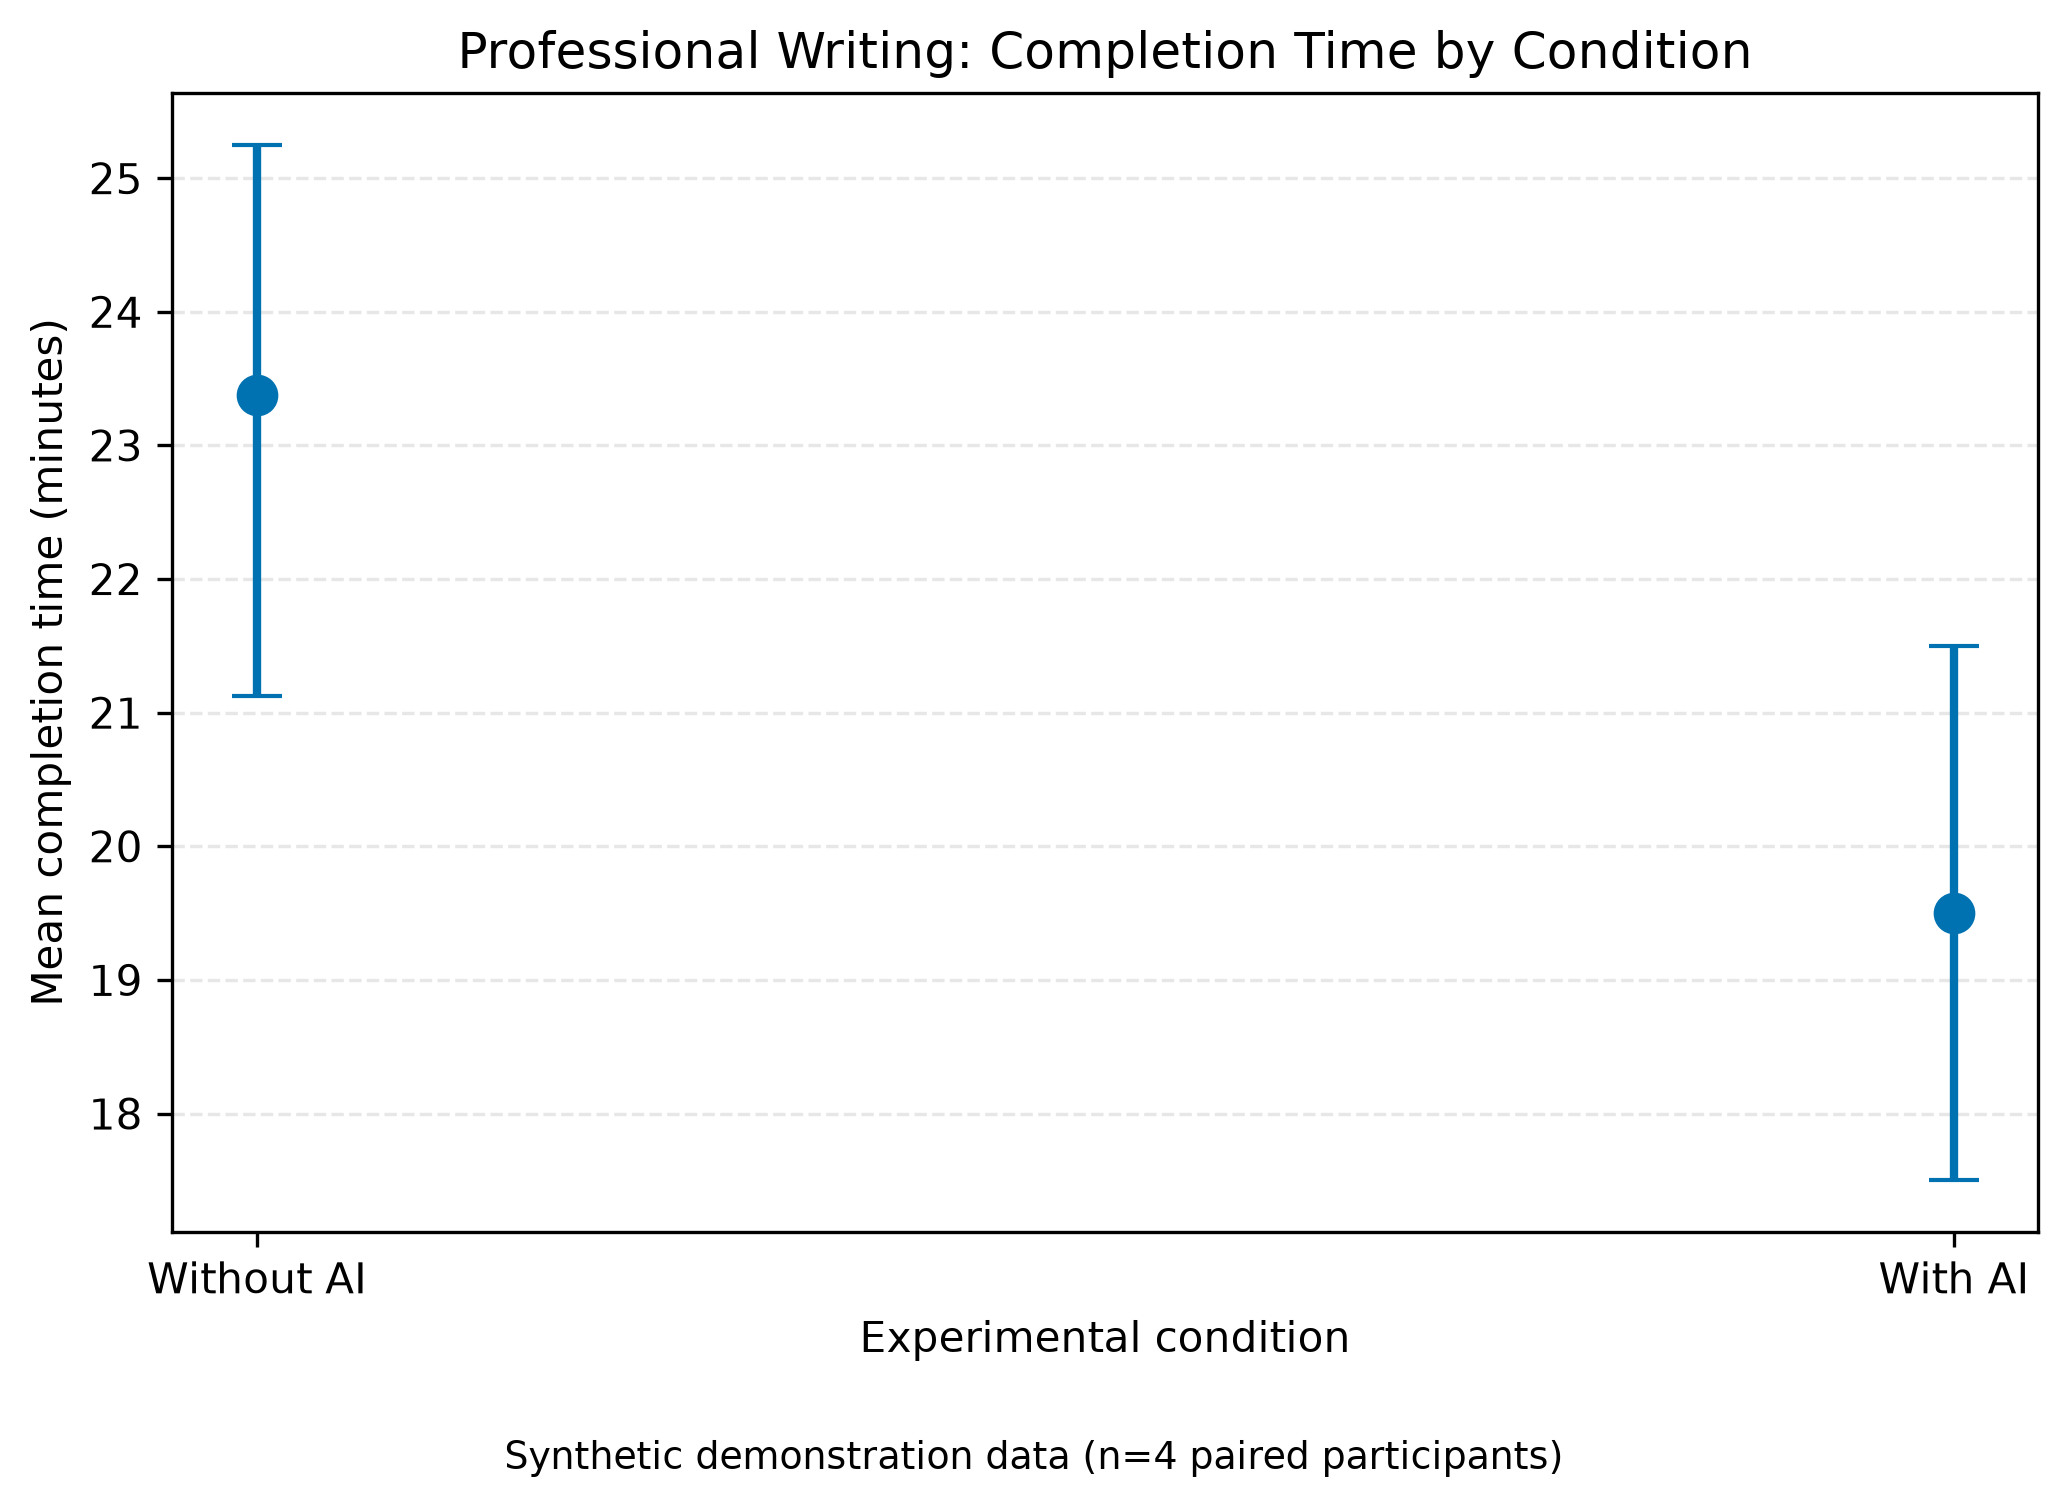

Figure 2: Completion Time Distribution


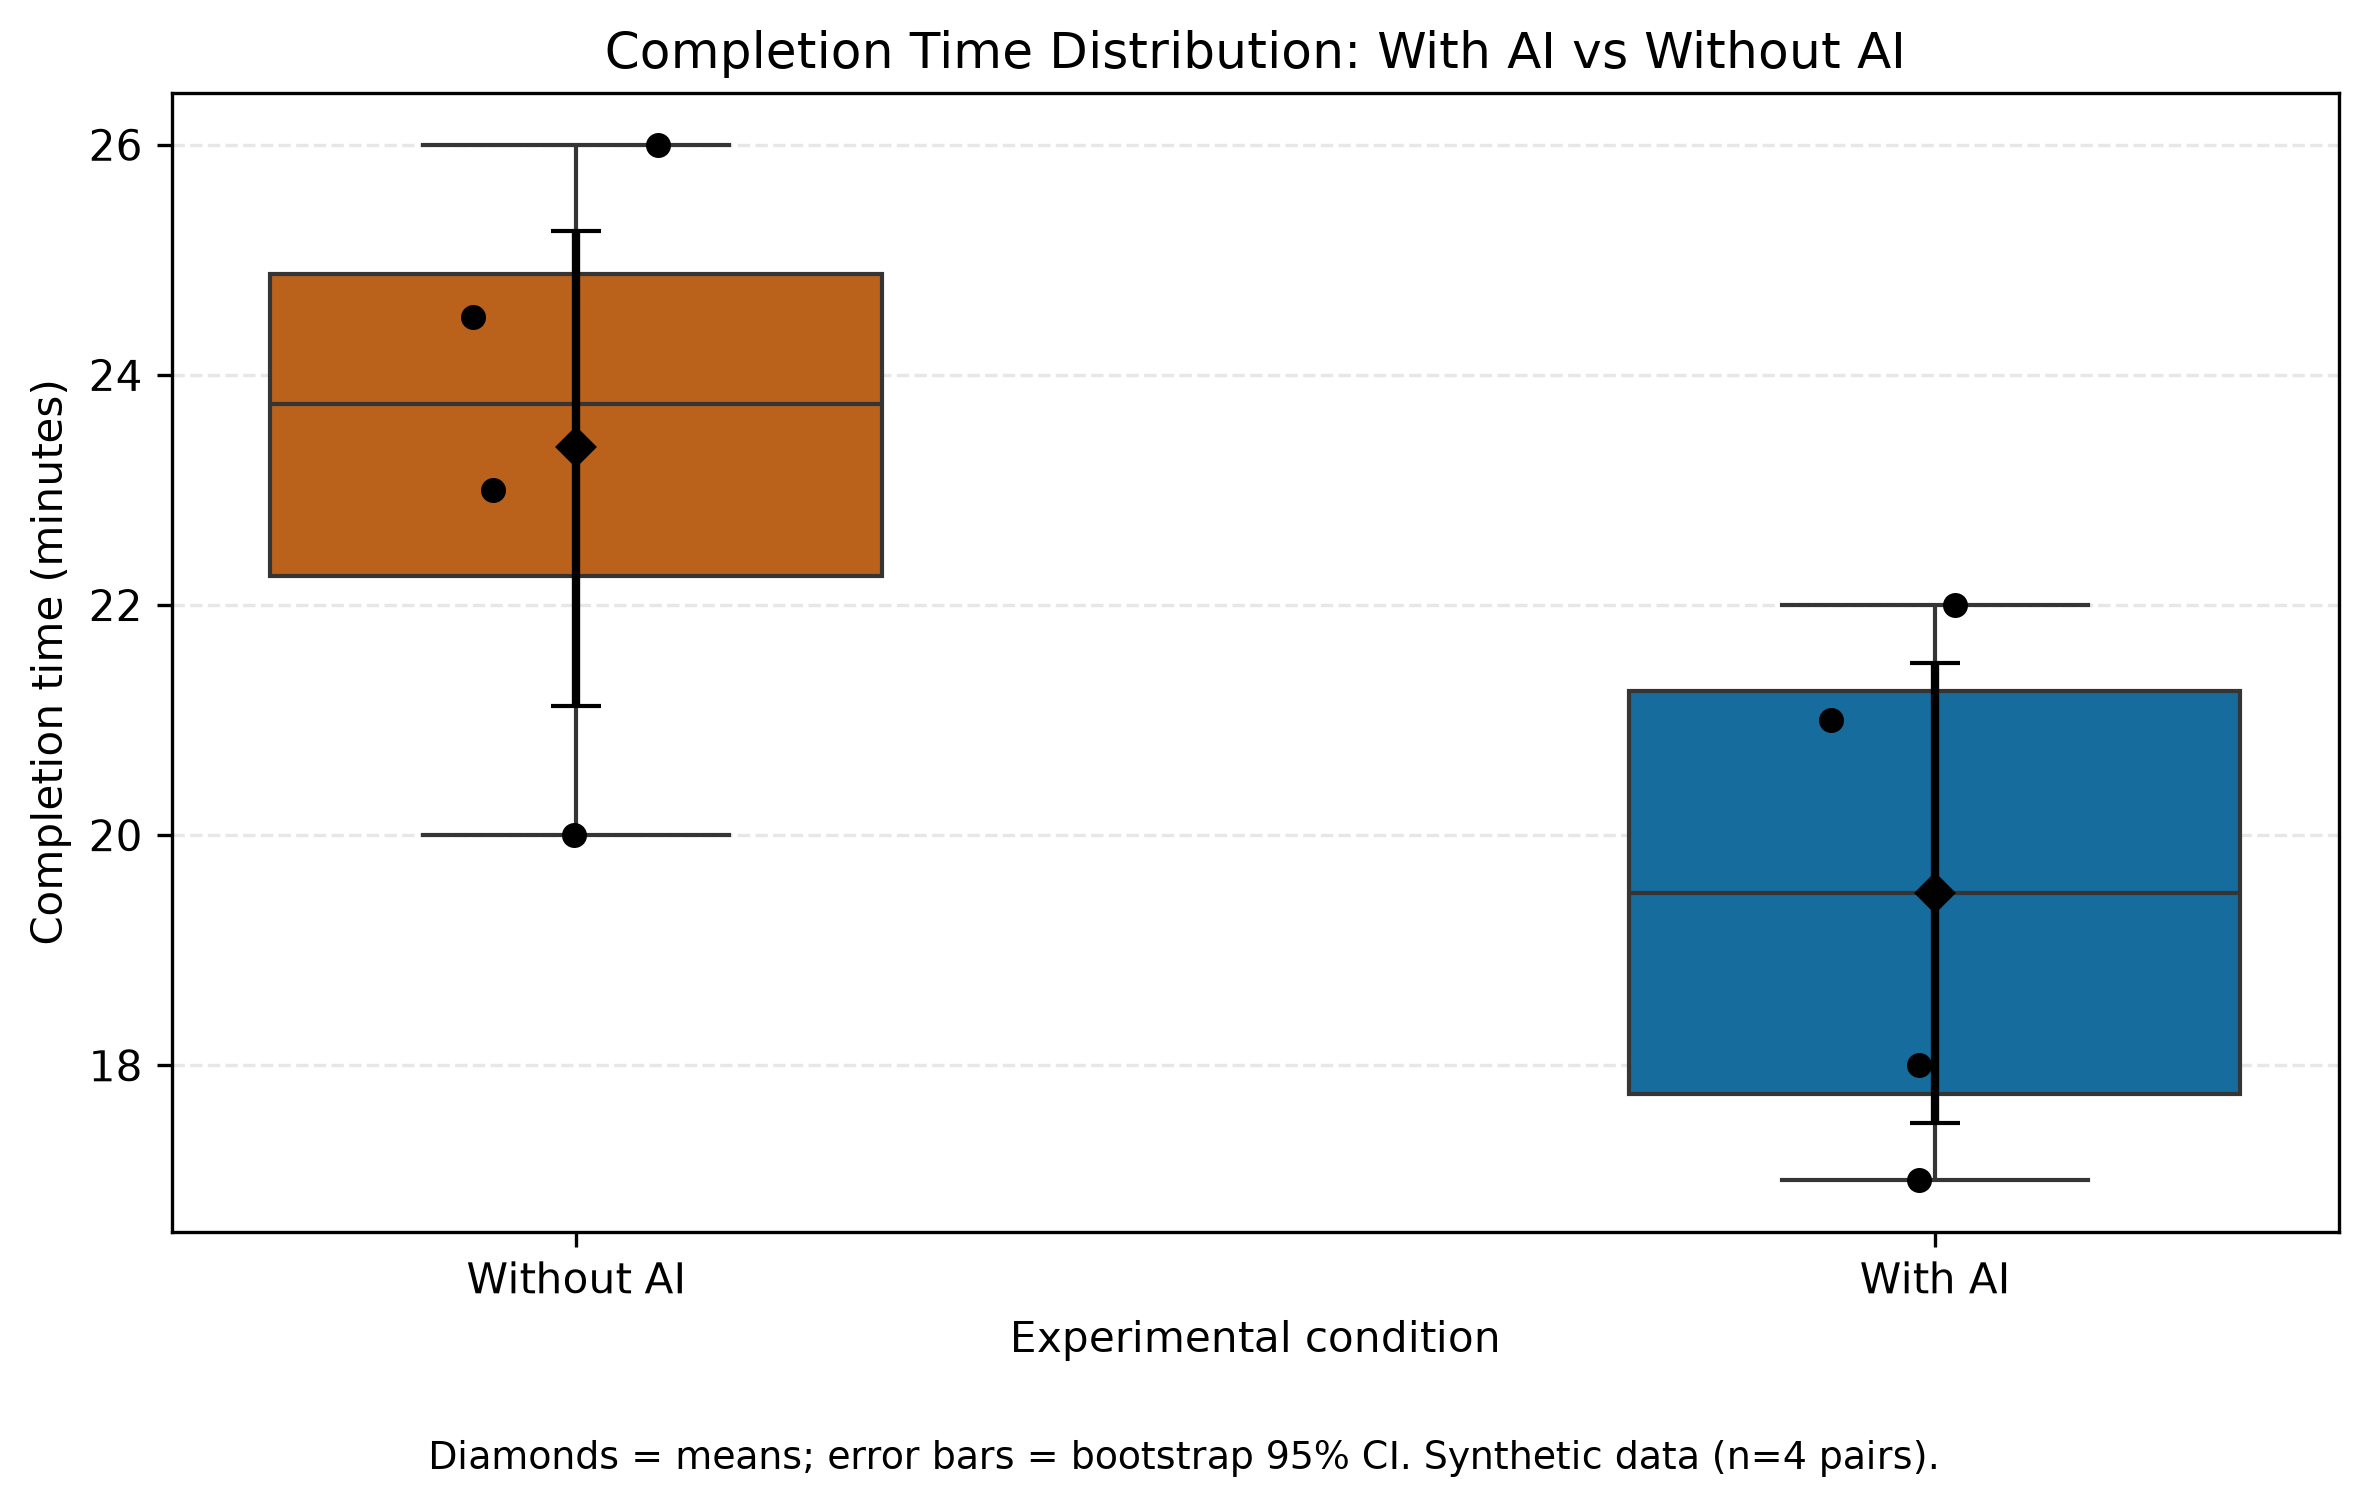

In [8]:

from IPython.display import Image, display

print("Figure 1: Mean Completion Time")
display(Image(filename=str(FIGURE_DIR / "fig1_latency_vs_load.png")))

print("Figure 2: Completion Time Distribution")
display(Image(filename=str(FIGURE_DIR / "fig2_distribution_boxplot.png")))




## Results and Interpretation

### Completion Time

The mean completion time was 19.50 minutes with AI and 23.38 minutes without AI.

The paired mean time saving was 3.88 minutes, with a 95% bootstrap confidence interval of [0.00, 6.25] minutes.

Since the confidence interval includes zero, the analysis does not provide conclusive evidence of a positive time-saving effect.

### Quality and Factual Accuracy

The mean quality score was 84.50 with AI and 81.63 without AI.

Factual accuracy was 95% with AI and 85% without AI.

However, the mean unsupported claim rate was higher with AI (15.71%) than without AI (9.17%).

### Limitations

This dataset contains only four paired participants and consists entirely of synthetic demonstration data.

The results demonstrate the reproducibility of the statistical analysis pipeline, not actual evidence that AI improves professional writing performance.

Warm-up filtering was not applied because this crossover dataset does not identify separate warm-up runs.

### Conclusion

The demonstration pipeline successfully calculates descriptive statistics, paired bootstrap confidence intervals, quality guardrails, and scientific visualizations.
